# Week 4 - Red Agent, Part 1 (DCGAN)
self-contained - needs `preprocessed_v2/` and `train_split.csv` from Dataset.ipynb.

trains a small DCGAN to generate synthetic faces. one deliberate simplification: training happens at **64x64**, not 160x160 - this is the standard DCGAN size (stable training, reasonable speed on a single GPU), not a mistake. your face recognition pipeline stays at 160x160, untouched. reconciling resolutions between genuine and generated images is a Week 5-6 problem (Blue Agent), not this one.

In [1]:
import os
os.chdir("/workspace")
print("working directory now:", os.getcwd())

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

working directory now: /workspace
device: cuda


In [2]:
base_path = "./celeba"
output_dir = os.path.join(base_path, "preprocessed_v2")
train_df = pd.read_csv(os.path.join(base_path, "train_split.csv"))

print("train images available:", len(train_df))

train images available: 32597


### dataset + dataloader
resizes down to 64x64, normalizes to [-1, 1] (matches the generator's Tanh output).

In [3]:
IMAGE_SIZE = 64
NOISE_DIM = 100
BATCH_SIZE = 128

gan_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

class FaceDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.df.iloc[idx]["file_name"])
        img = Image.open(img_path).convert("RGB")
        return self.transform(img)

dataset = FaceDataset(train_df, output_dir, gan_transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=8)

print("dataset size:", len(dataset))
print("batches per epoch:", len(dataloader))

dataset size: 32597
batches per epoch: 255


### quick check - one real batch looks right

batch shape: torch.Size([128, 3, 64, 64])


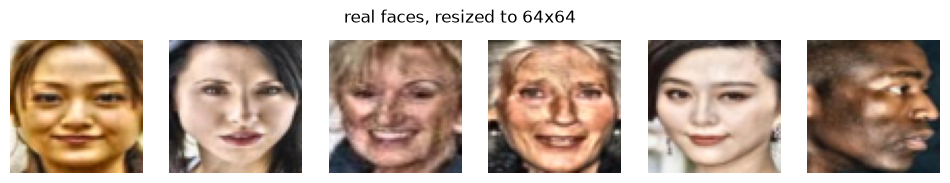

In [4]:
real_batch = next(iter(dataloader))
print("batch shape:", real_batch.shape)

fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for i in range(6):
    img = (real_batch[i] * 0.5 + 0.5).clip(0, 1)
    axes[i].imshow(img.permute(1, 2, 0).numpy())
    axes[i].axis("off")
plt.suptitle("real faces, resized to 64x64")
plt.show()

### generator
noise vector -> transposed convolutions (upsampling) -> 64x64 face. Tanh output keeps pixels in [-1, 1], matching the normalization above.

In [5]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100, feature_maps=64):
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, feature_maps * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(feature_maps * 8),
            nn.ReLU(True),
            # 4x4 -> 8x8
            nn.ConvTranspose2d(feature_maps * 8, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4),
            nn.ReLU(True),
            # 8x8 -> 16x16
            nn.ConvTranspose2d(feature_maps * 4, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(True),
            # 16x16 -> 32x32
            nn.ConvTranspose2d(feature_maps * 2, feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(True),
            # 32x32 -> 64x64
            nn.ConvTranspose2d(feature_maps, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.main(x)

### discriminator
mirror of the generator - real/fake CNN classifier, outputs a single probability per image.

In [6]:
class Discriminator(nn.Module):
    def __init__(self, feature_maps=64):
        super().__init__()
        self.main = nn.Sequential(
            # 64x64 -> 32x32
            nn.Conv2d(3, feature_maps, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # 32x32 -> 16x16
            nn.Conv2d(feature_maps, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # 16x16 -> 8x8
            nn.Conv2d(feature_maps * 2, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # 8x8 -> 4x4
            nn.Conv2d(feature_maps * 4, feature_maps * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # 4x4 -> 1x1
            nn.Conv2d(feature_maps * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.main(x).view(-1)

### build the models
weight init follows the original DCGAN paper - random init makes training unstable.

In [7]:
def weights_init(m):
    classname = m.__class__.__name__
    if "Conv" in classname:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in classname:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

generator = Generator(NOISE_DIM).to(device)
discriminator = Discriminator().to(device)

generator.apply(weights_init)
discriminator.apply(weights_init)

print("generator parameters:", sum(p.numel() for p in generator.parameters()))
print("discriminator parameters:", sum(p.numel() for p in discriminator.parameters()))

generator parameters: 3576704
discriminator parameters: 2765568


### loss + optimizers
standard DCGAN hyperparameters - lr=0.0002, betas=(0.5, 0.999). these are not arbitrary, the paper found these specific values needed for stable adversarial training.

In [8]:
criterion = nn.BCELoss()

optimizer_g = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

real_label = 1.0
fake_label = 0.0

# fixed noise so we can watch the SAME synthetic faces improve across epochs
fixed_noise = torch.randn(16, NOISE_DIM, 1, 1, device=device)

### training loop
each batch: train discriminator on real images, then on fake images, then train generator to fool the discriminator. saves a sample grid every epoch so you can watch it improve.

on GPU this should take a few minutes per epoch. on CPU, expect it to be slow - consider lowering `num_epochs` for a first test run.

resuming from epoch 25
epoch 26/50  batch 0/255  loss_d: 0.3218  loss_g: 3.4922  |  0.0 min elapsed
epoch 26/50  batch 100/255  loss_d: 0.3188  loss_g: 3.2083  |  0.0 min elapsed
epoch 26/50  batch 200/255  loss_d: 0.6074  loss_g: 2.5554  |  0.1 min elapsed


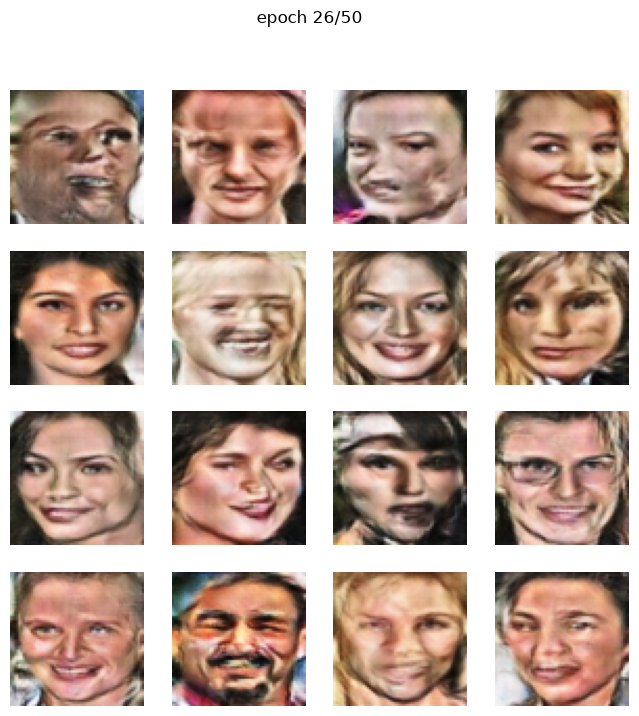

epoch 27/50  batch 0/255  loss_d: 0.4424  loss_g: 2.2252  |  0.1 min elapsed
epoch 27/50  batch 100/255  loss_d: 0.2953  loss_g: 3.7886  |  0.2 min elapsed
epoch 27/50  batch 200/255  loss_d: 0.2811  loss_g: 3.5547  |  0.2 min elapsed


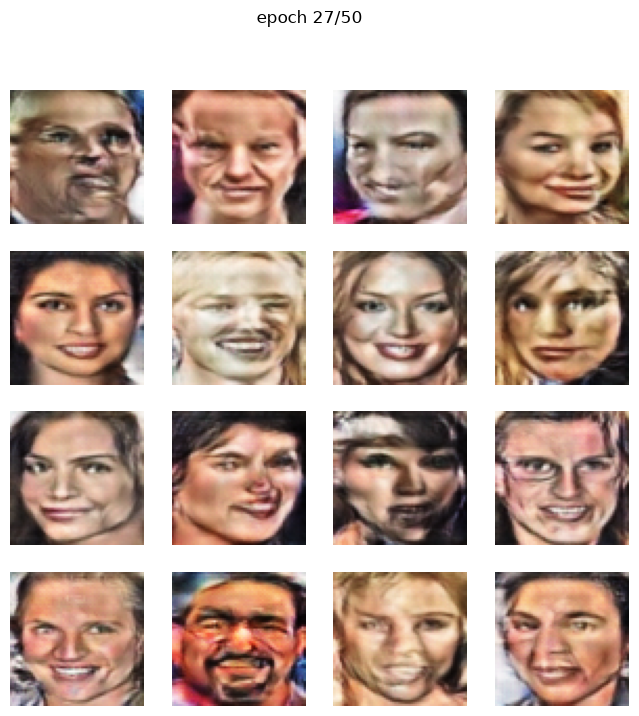

epoch 28/50  batch 0/255  loss_d: 1.8258  loss_g: 7.1449  |  0.2 min elapsed
epoch 28/50  batch 100/255  loss_d: 0.3637  loss_g: 3.1206  |  0.3 min elapsed
epoch 28/50  batch 200/255  loss_d: 0.4116  loss_g: 3.9473  |  0.3 min elapsed


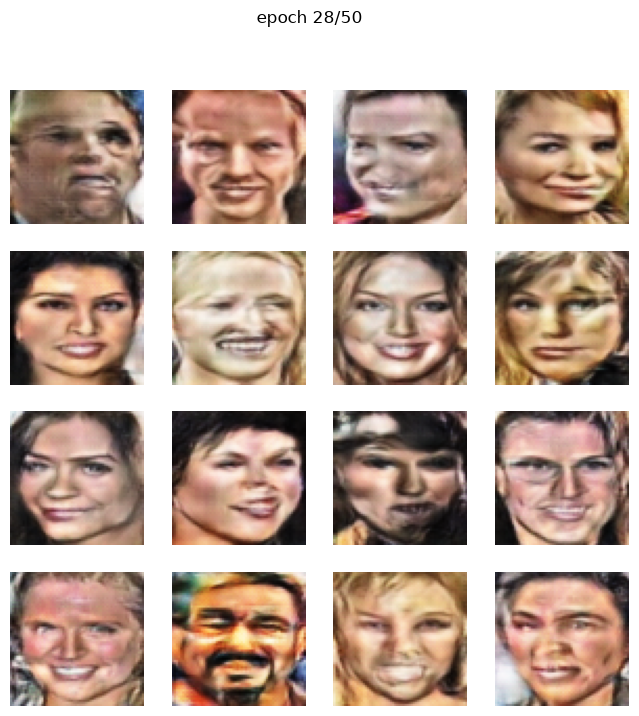

epoch 29/50  batch 0/255  loss_d: 0.6640  loss_g: 3.3409  |  0.3 min elapsed
epoch 29/50  batch 100/255  loss_d: 0.5112  loss_g: 4.1310  |  0.4 min elapsed
epoch 29/50  batch 200/255  loss_d: 0.4282  loss_g: 4.8550  |  0.4 min elapsed


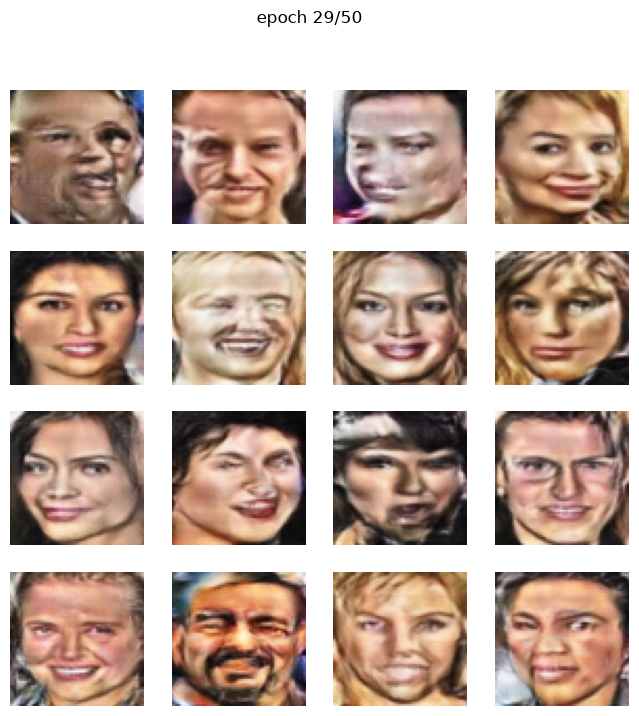

epoch 30/50  batch 0/255  loss_d: 0.3774  loss_g: 3.5692  |  0.5 min elapsed
epoch 30/50  batch 100/255  loss_d: 0.5441  loss_g: 2.1489  |  0.5 min elapsed
epoch 30/50  batch 200/255  loss_d: 0.4287  loss_g: 2.5987  |  0.5 min elapsed


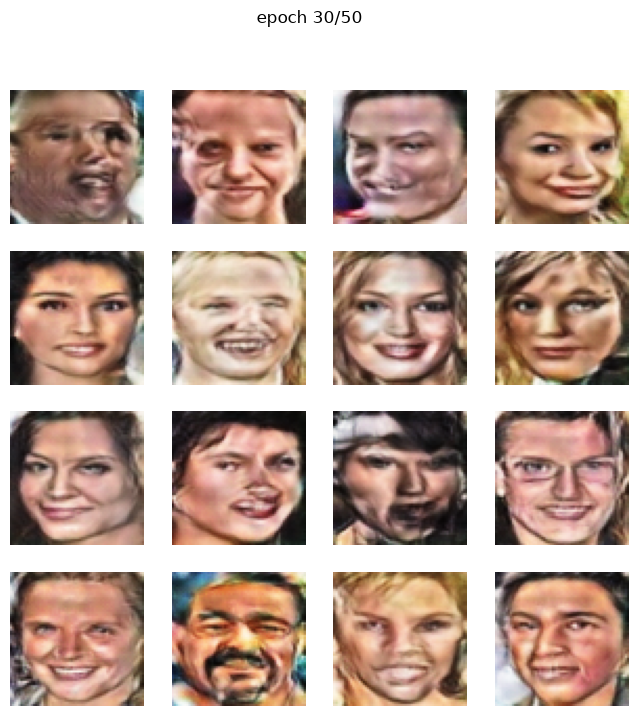

epoch 31/50  batch 0/255  loss_d: 0.4189  loss_g: 5.1809  |  0.6 min elapsed
epoch 31/50  batch 100/255  loss_d: 0.2828  loss_g: 3.9981  |  0.6 min elapsed
epoch 31/50  batch 200/255  loss_d: 0.2502  loss_g: 3.3664  |  0.6 min elapsed


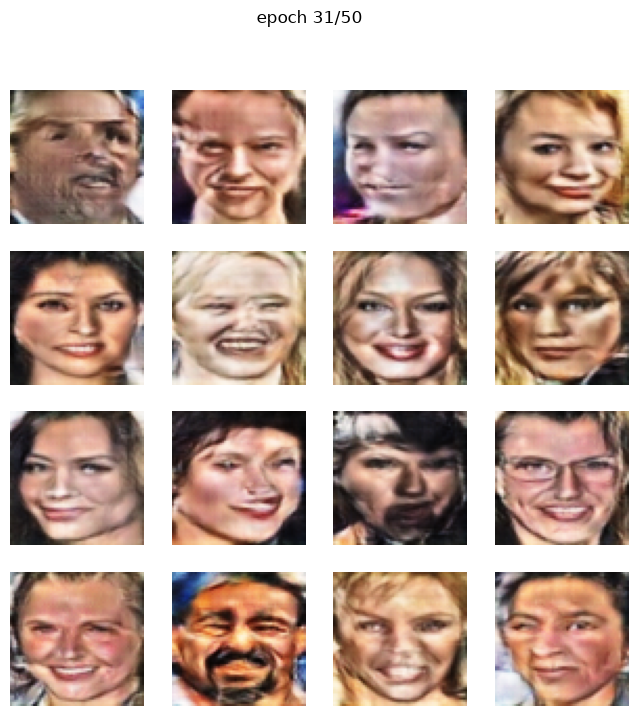

epoch 32/50  batch 0/255  loss_d: 0.7870  loss_g: 4.0714  |  0.7 min elapsed
epoch 32/50  batch 100/255  loss_d: 0.5100  loss_g: 5.1795  |  0.7 min elapsed
epoch 32/50  batch 200/255  loss_d: 0.3169  loss_g: 4.1590  |  0.8 min elapsed


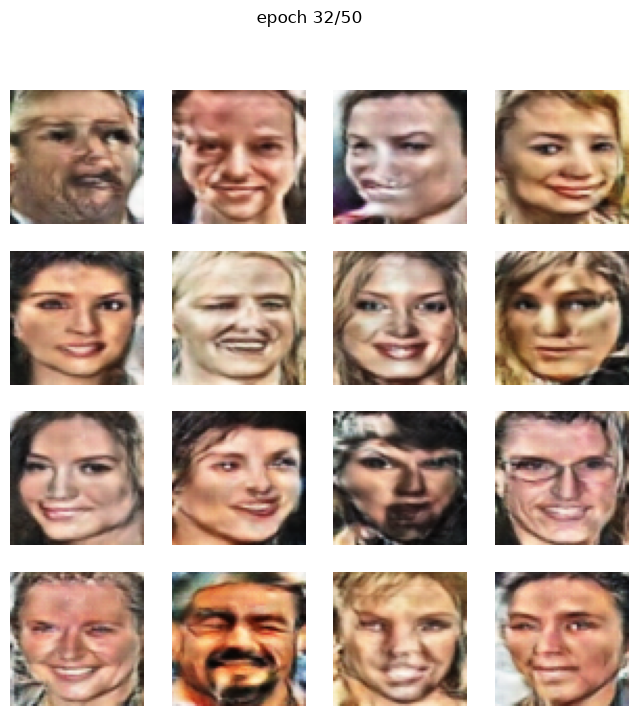

epoch 33/50  batch 0/255  loss_d: 0.5906  loss_g: 1.7163  |  0.8 min elapsed
epoch 33/50  batch 100/255  loss_d: 0.3829  loss_g: 2.4510  |  0.8 min elapsed
epoch 33/50  batch 200/255  loss_d: 0.3057  loss_g: 3.0463  |  0.9 min elapsed


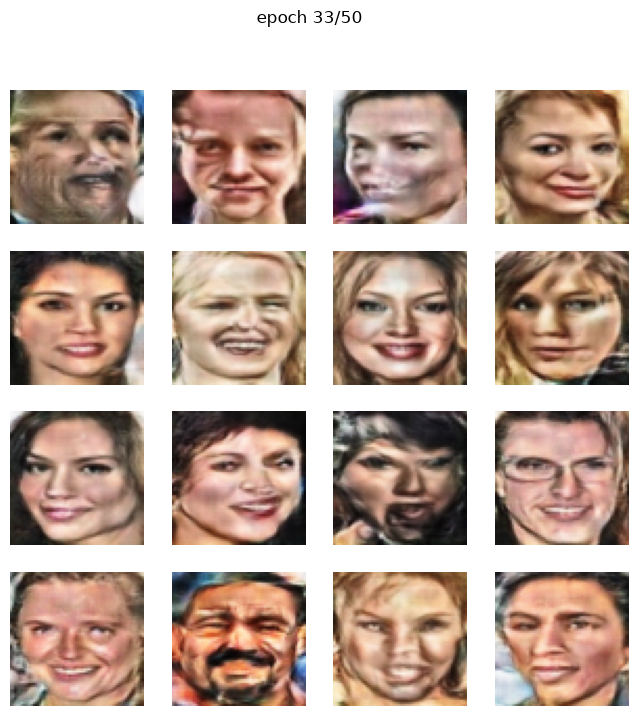

epoch 34/50  batch 0/255  loss_d: 0.3504  loss_g: 2.3482  |  0.9 min elapsed
epoch 34/50  batch 100/255  loss_d: 0.7347  loss_g: 5.6023  |  0.9 min elapsed
epoch 34/50  batch 200/255  loss_d: 0.6495  loss_g: 4.1738  |  1.0 min elapsed


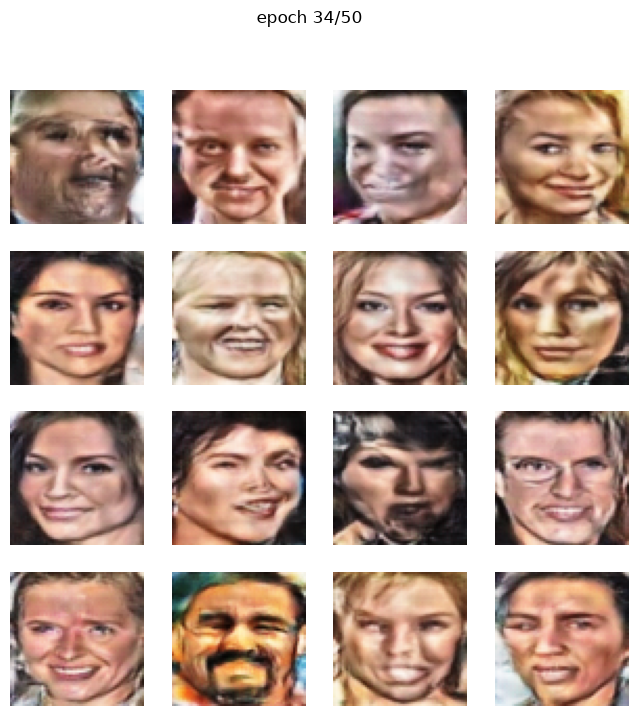

epoch 35/50  batch 0/255  loss_d: 0.3184  loss_g: 3.4609  |  1.0 min elapsed
epoch 35/50  batch 100/255  loss_d: 0.3430  loss_g: 2.3327  |  1.0 min elapsed
epoch 35/50  batch 200/255  loss_d: 0.3550  loss_g: 2.7048  |  1.1 min elapsed


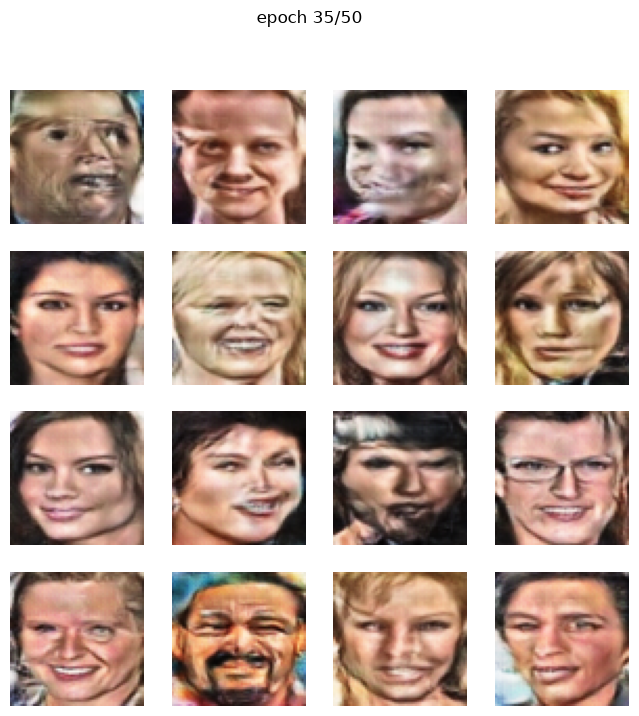

epoch 36/50  batch 0/255  loss_d: 0.5948  loss_g: 2.1837  |  1.1 min elapsed
epoch 36/50  batch 100/255  loss_d: 0.2364  loss_g: 3.3468  |  1.2 min elapsed
epoch 36/50  batch 200/255  loss_d: 0.2708  loss_g: 2.8678  |  1.2 min elapsed


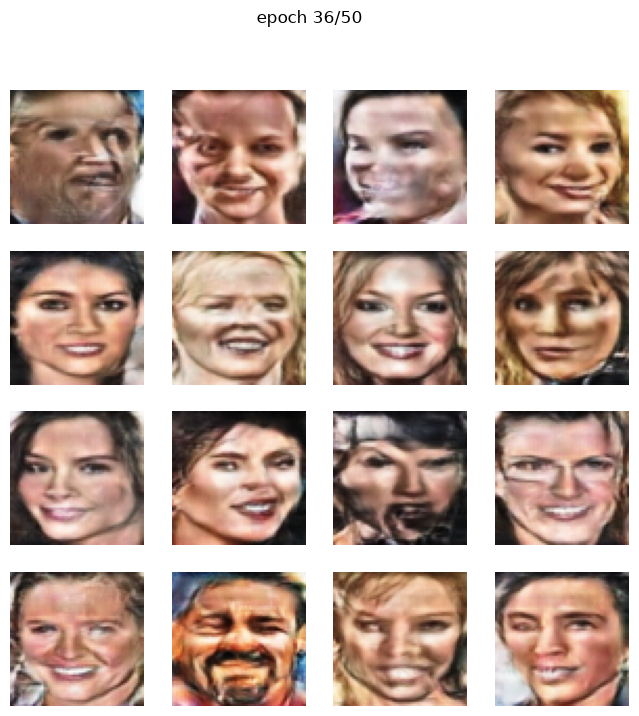

epoch 37/50  batch 0/255  loss_d: 0.6398  loss_g: 1.7016  |  1.2 min elapsed
epoch 37/50  batch 100/255  loss_d: 0.8439  loss_g: 4.2212  |  1.3 min elapsed
epoch 37/50  batch 200/255  loss_d: 0.3593  loss_g: 3.8504  |  1.3 min elapsed


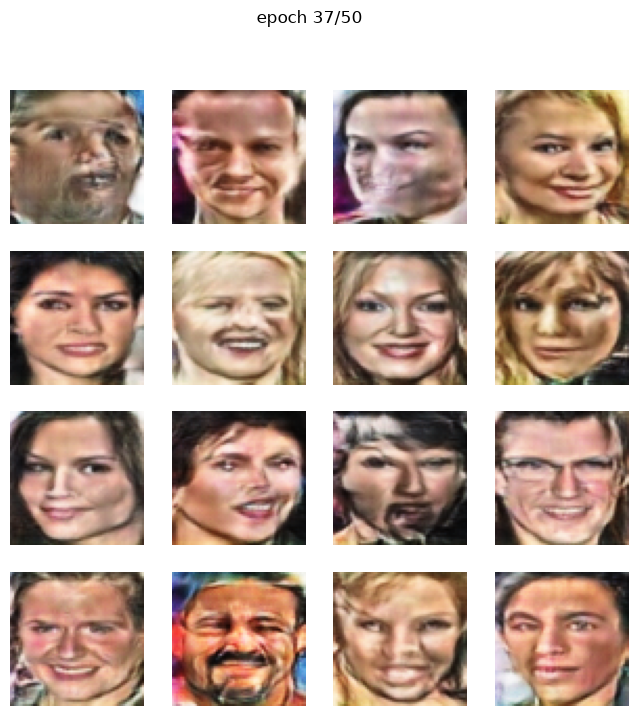

epoch 38/50  batch 0/255  loss_d: 0.4261  loss_g: 2.5851  |  1.3 min elapsed
epoch 38/50  batch 100/255  loss_d: 0.2983  loss_g: 3.8626  |  1.4 min elapsed
epoch 38/50  batch 200/255  loss_d: 0.3774  loss_g: 2.9576  |  1.4 min elapsed


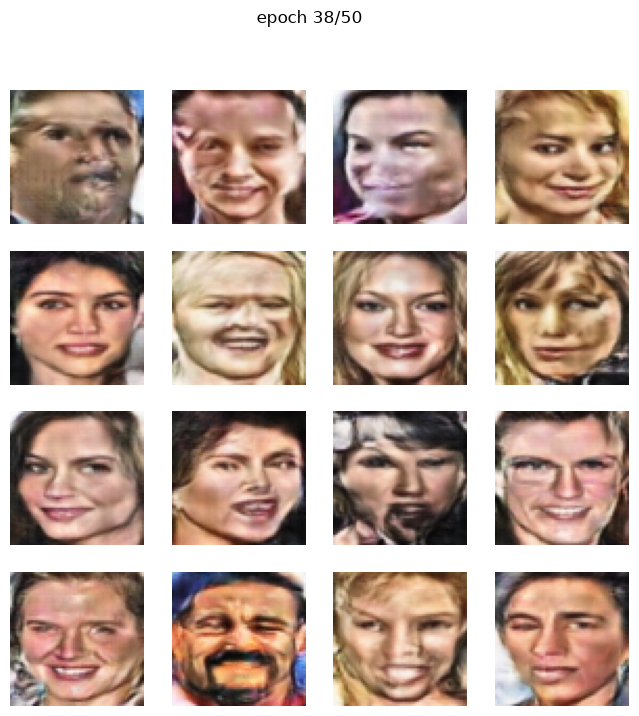

epoch 39/50  batch 0/255  loss_d: 0.3030  loss_g: 3.3518  |  1.5 min elapsed
epoch 39/50  batch 100/255  loss_d: 0.3425  loss_g: 3.2004  |  1.5 min elapsed
epoch 39/50  batch 200/255  loss_d: 0.2921  loss_g: 3.2587  |  1.5 min elapsed


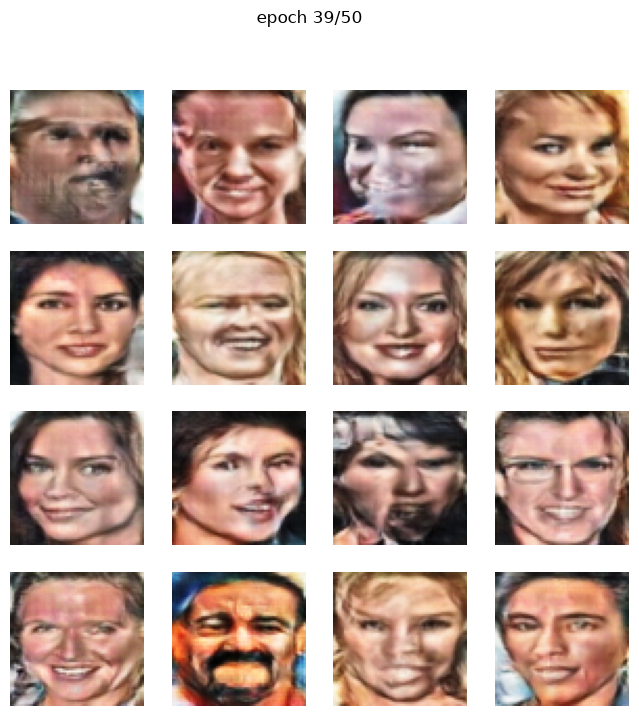

epoch 40/50  batch 0/255  loss_d: 0.5065  loss_g: 6.0663  |  1.6 min elapsed
epoch 40/50  batch 100/255  loss_d: 0.5721  loss_g: 4.8987  |  1.6 min elapsed
epoch 40/50  batch 200/255  loss_d: 0.2801  loss_g: 2.5899  |  1.6 min elapsed


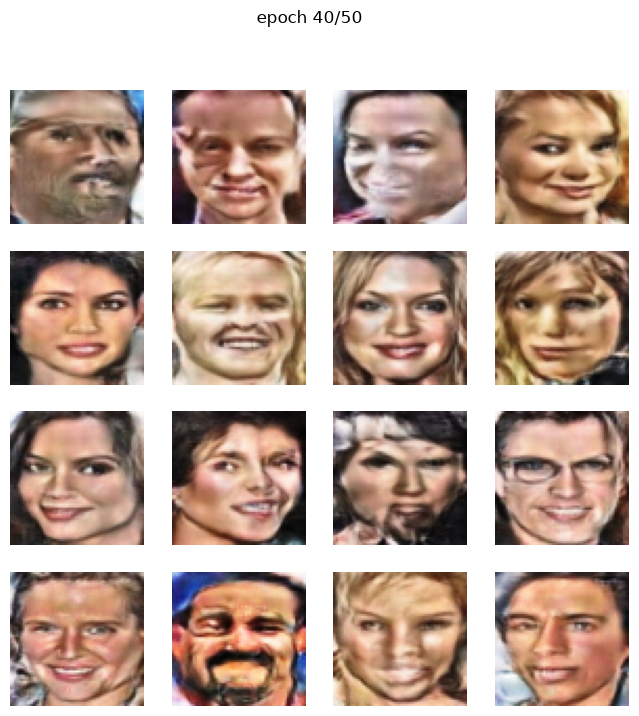

epoch 41/50  batch 0/255  loss_d: 0.9796  loss_g: 0.8369  |  1.7 min elapsed
epoch 41/50  batch 100/255  loss_d: 1.0303  loss_g: 1.4819  |  1.7 min elapsed
epoch 41/50  batch 200/255  loss_d: 0.3626  loss_g: 2.3307  |  1.8 min elapsed


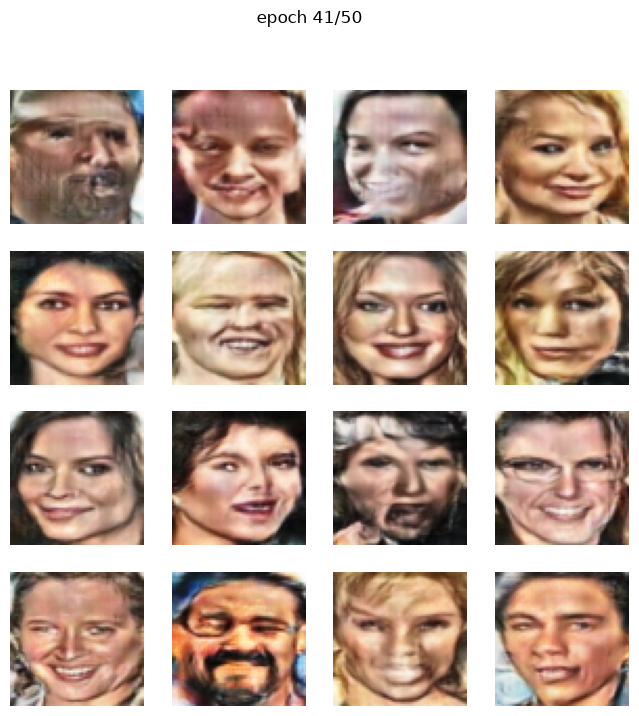

epoch 42/50  batch 0/255  loss_d: 0.3560  loss_g: 3.9741  |  1.8 min elapsed
epoch 42/50  batch 100/255  loss_d: 0.3374  loss_g: 3.2270  |  1.8 min elapsed
epoch 42/50  batch 200/255  loss_d: 0.2977  loss_g: 4.4028  |  1.9 min elapsed


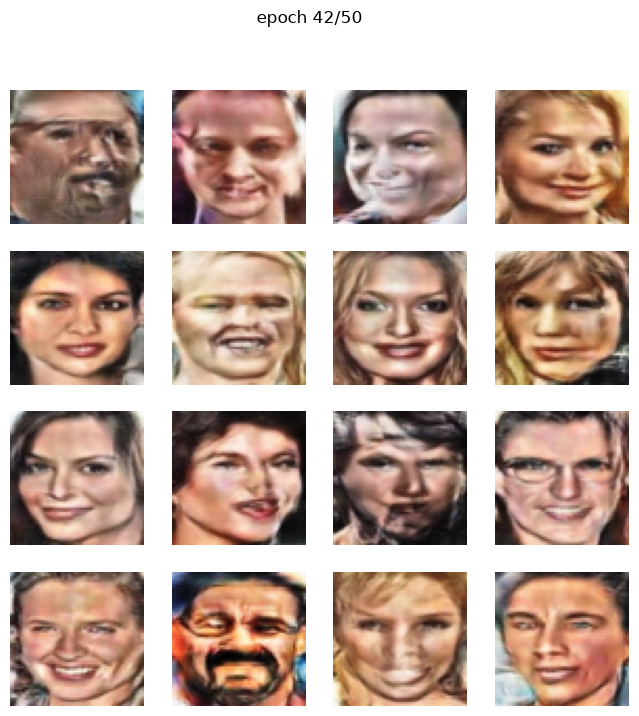

epoch 43/50  batch 0/255  loss_d: 1.7862  loss_g: 0.3799  |  1.9 min elapsed
epoch 43/50  batch 100/255  loss_d: 0.2216  loss_g: 2.8347  |  1.9 min elapsed
epoch 43/50  batch 200/255  loss_d: 1.8811  loss_g: 0.3238  |  2.0 min elapsed


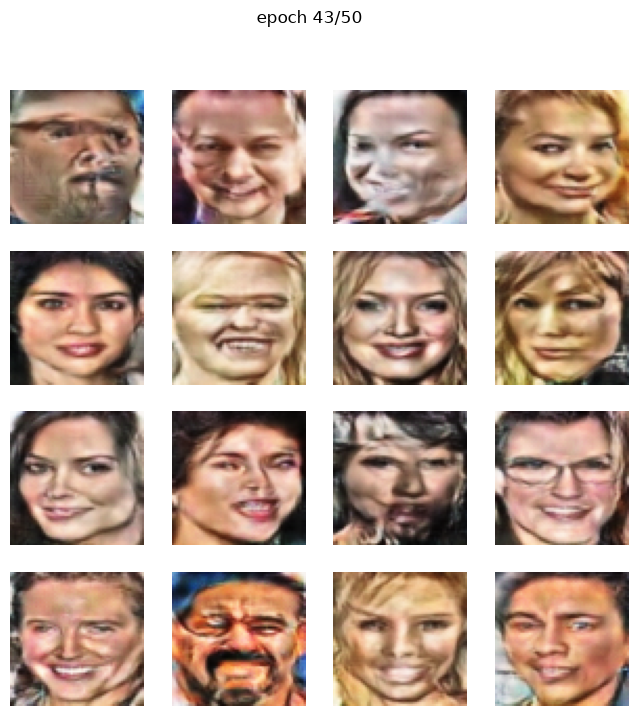

epoch 44/50  batch 0/255  loss_d: 0.4232  loss_g: 3.1141  |  2.0 min elapsed
epoch 44/50  batch 100/255  loss_d: 0.2389  loss_g: 3.2075  |  2.1 min elapsed
epoch 44/50  batch 200/255  loss_d: 0.2394  loss_g: 2.9060  |  2.1 min elapsed


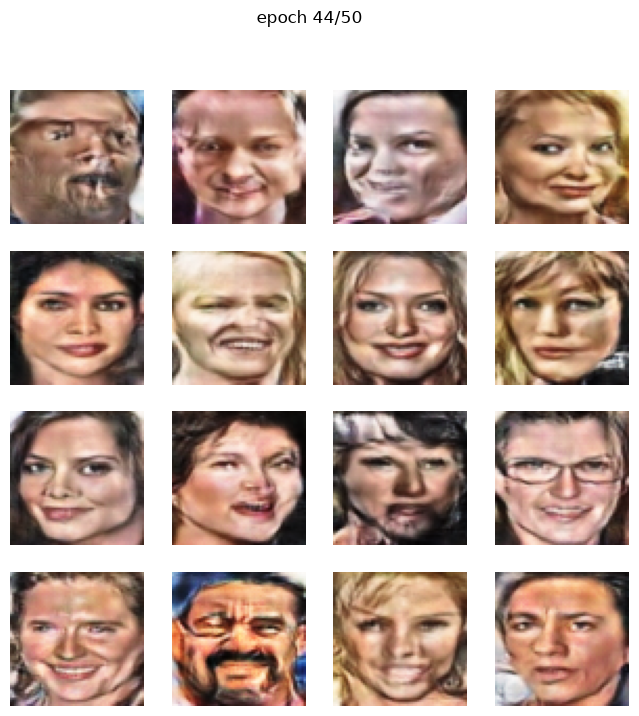

epoch 45/50  batch 0/255  loss_d: 0.2644  loss_g: 3.4314  |  2.1 min elapsed
epoch 45/50  batch 100/255  loss_d: 1.6262  loss_g: 0.7053  |  2.2 min elapsed
epoch 45/50  batch 200/255  loss_d: 0.3555  loss_g: 4.1573  |  2.2 min elapsed


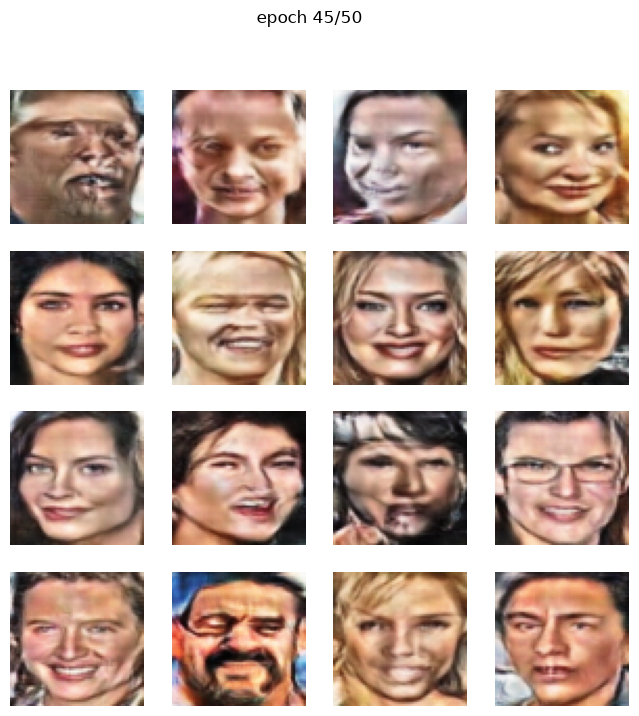

epoch 46/50  batch 0/255  loss_d: 0.2781  loss_g: 3.8643  |  2.2 min elapsed
epoch 46/50  batch 100/255  loss_d: 0.4100  loss_g: 1.9553  |  2.3 min elapsed
epoch 46/50  batch 200/255  loss_d: 0.4803  loss_g: 5.2729  |  2.3 min elapsed


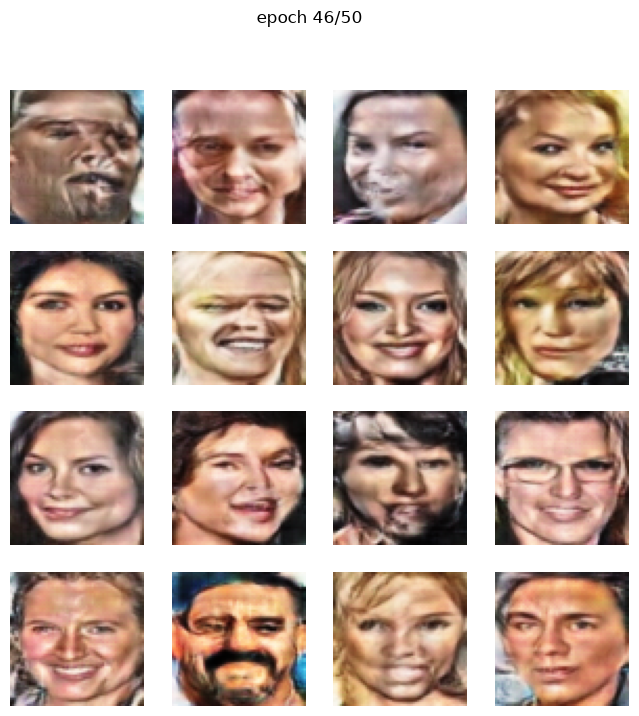

epoch 47/50  batch 0/255  loss_d: 0.5107  loss_g: 3.4004  |  2.4 min elapsed
epoch 47/50  batch 100/255  loss_d: 0.6690  loss_g: 5.4740  |  2.4 min elapsed
epoch 47/50  batch 200/255  loss_d: 3.4720  loss_g: 0.3903  |  2.4 min elapsed


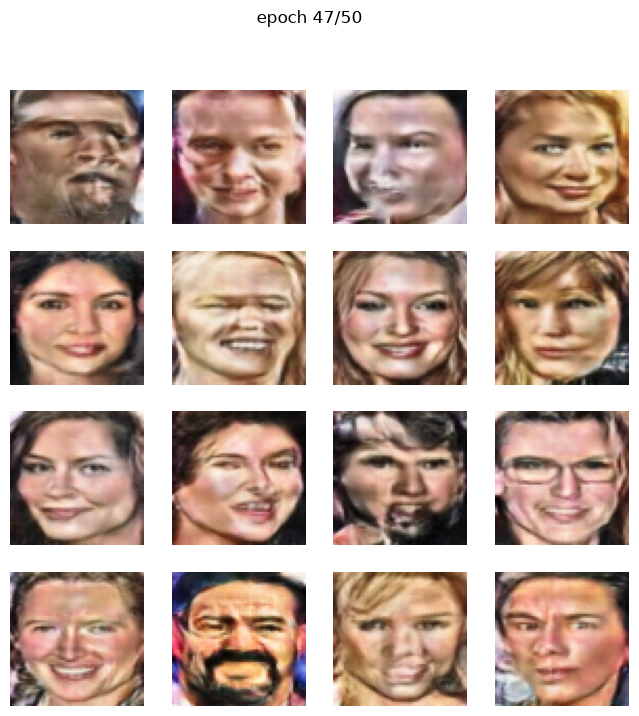

epoch 48/50  batch 0/255  loss_d: 0.3410  loss_g: 4.0537  |  2.5 min elapsed
epoch 48/50  batch 100/255  loss_d: 0.4450  loss_g: 5.6260  |  2.5 min elapsed
epoch 48/50  batch 200/255  loss_d: 0.2600  loss_g: 3.1587  |  2.5 min elapsed


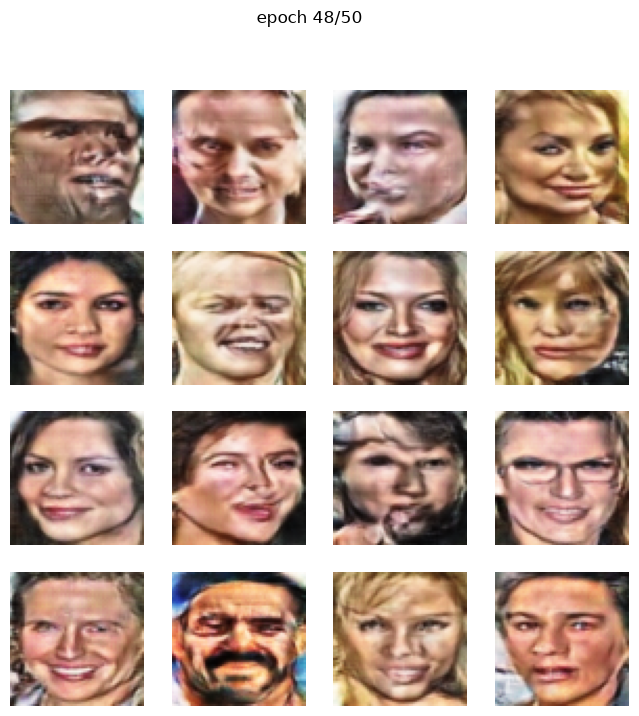

epoch 49/50  batch 0/255  loss_d: 0.6870  loss_g: 3.8881  |  2.6 min elapsed
epoch 49/50  batch 100/255  loss_d: 0.2513  loss_g: 2.9977  |  2.6 min elapsed
epoch 49/50  batch 200/255  loss_d: 0.8198  loss_g: 1.5216  |  2.7 min elapsed


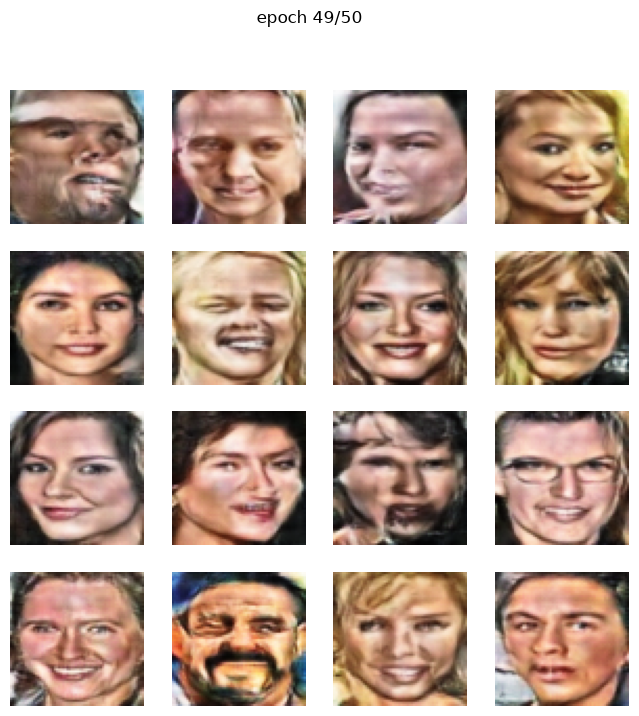

epoch 50/50  batch 0/255  loss_d: 0.3170  loss_g: 2.0676  |  2.7 min elapsed
epoch 50/50  batch 100/255  loss_d: 0.2066  loss_g: 3.7837  |  2.7 min elapsed
epoch 50/50  batch 200/255  loss_d: 0.5013  loss_g: 5.2441  |  2.8 min elapsed


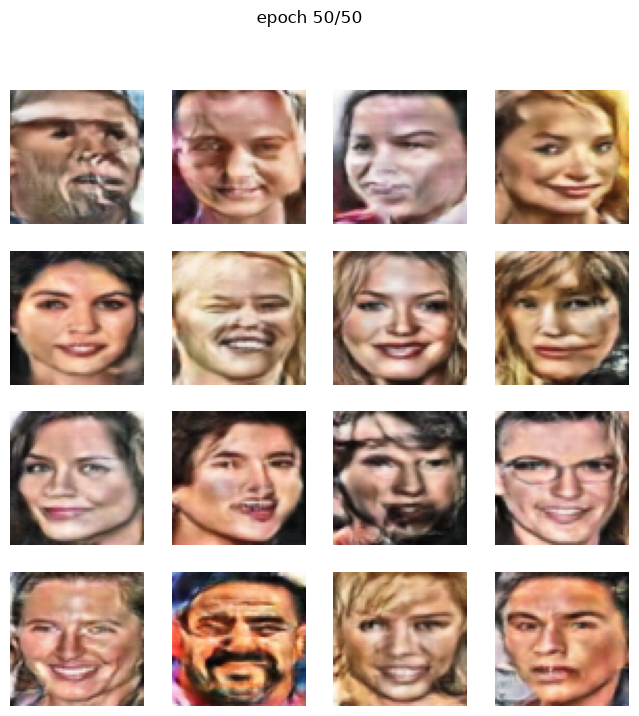

training done


In [9]:
checkpoint_path = os.path.join(base_path, "dcgan_checkpoint.pth")
num_epochs = 50

start_epoch = 0
g_losses = []
d_losses = []

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    generator.load_state_dict(checkpoint["generator"])
    discriminator.load_state_dict(checkpoint["discriminator"])
    optimizer_g.load_state_dict(checkpoint["optimizer_g"])
    optimizer_d.load_state_dict(checkpoint["optimizer_d"])
    start_epoch = checkpoint["epoch"] + 1
    g_losses = checkpoint["g_losses"]
    d_losses = checkpoint["d_losses"]
    print(f"resuming from epoch {start_epoch}")
else:
    print("no checkpoint found, starting fresh")

start_time = time.time()

for epoch in range(start_epoch, num_epochs):
    for i, real_images in enumerate(dataloader):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # --- train discriminator on real images ---
        discriminator.zero_grad()
        labels = torch.full((batch_size,), real_label, device=device)
        output = discriminator(real_images)
        loss_d_real = criterion(output, labels)
        loss_d_real.backward()

        # --- train discriminator on fake images ---
        noise = torch.randn(batch_size, NOISE_DIM, 1, 1, device=device)
        fake_images = generator(noise)
        labels.fill_(fake_label)
        output = discriminator(fake_images.detach())  # detach - don't update generator here
        loss_d_fake = criterion(output, labels)
        loss_d_fake.backward()

        loss_d = loss_d_real + loss_d_fake
        optimizer_d.step()

        # --- train generator (wants discriminator to say "real" on fakes) ---
        generator.zero_grad()
        labels.fill_(real_label)
        output = discriminator(fake_images)
        loss_g = criterion(output, labels)
        loss_g.backward()
        optimizer_g.step()

        if i % 100 == 0:
            elapsed = time.time() - start_time
            print(f"epoch {epoch+1}/{num_epochs}  batch {i}/{len(dataloader)}  loss_d: {loss_d.item():.4f}  loss_g: {loss_g.item():.4f}  |  {elapsed/60:.1f} min elapsed")

    g_losses.append(loss_g.item())
    d_losses.append(loss_d.item())

    # visualize progress on the SAME fixed noise every epoch
    with torch.no_grad():
        fake_samples = generator(fixed_noise).detach().cpu()

    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for ax, img in zip(axes.flatten(), fake_samples):
        img_display = (img * 0.5 + 0.5).clip(0, 1)
        ax.imshow(img_display.permute(1, 2, 0).numpy())
        ax.axis("off")
    plt.suptitle(f"epoch {epoch+1}/{num_epochs}")
    plt.show()

    # save checkpoint after every epoch - this is what makes resuming possible
    torch.save({
        "epoch": epoch,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_g": optimizer_g.state_dict(),
        "optimizer_d": optimizer_d.state_dict(),
        "g_losses": g_losses,
        "d_losses": d_losses,
    }, checkpoint_path)

print("training done")

### plot losses

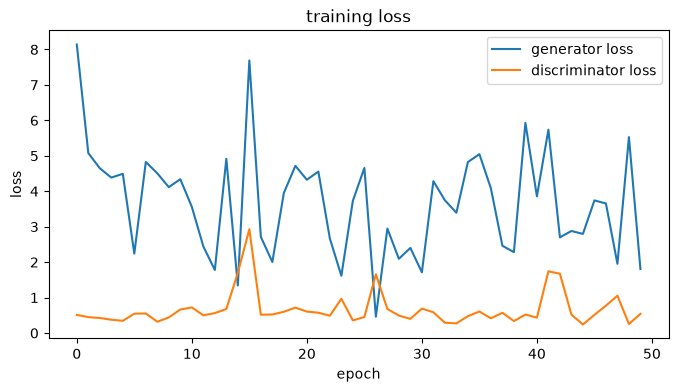

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(g_losses, label="generator loss")
plt.plot(d_losses, label="discriminator loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("training loss")
plt.show()

### save the trained generator
this is the artifact the rest of VigilantFace uses - the Blue Agent (Week 6) needs synthetic faces from this generator to learn what a GAN-generated face looks like.

In [11]:
generator_path = os.path.join(base_path, "generator_dcgan.pth")
torch.save(generator.state_dict(), generator_path)
print("generator saved to:", generator_path)

generator saved to: ./celeba/generator_dcgan.pth


### milestone check - generate one synthetic face

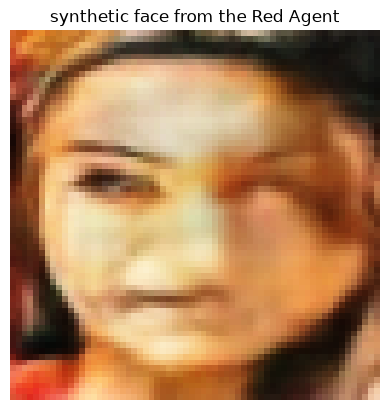

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)

In [12]:
generator.eval()
with torch.no_grad():
    noise = torch.randn(1, NOISE_DIM, 1, 1, device=device)
    synthetic_face = generator(noise).cpu().squeeze(0)

synthetic_face_display = (synthetic_face * 0.5 + 0.5).clip(0, 1)

plt.imshow(synthetic_face_display.permute(1, 2, 0).numpy())
plt.axis("off")
plt.title("synthetic face from the Red Agent")
plt.show()

generator.train()  # back to training mode, in case you continue training later

### what's next
- if faces look blurry/noisy after 25 epochs, that's normal early DCGAN behavior - more epochs (40-50) usually sharpens them. watch the per-epoch grids above rather than judging from the first few.
- this generator is now the Red Agent's GAN component. Week 4 part 2 and Week 5 add FGSM/PGD attacks (ART library) using your FaceNet model from Task 2.
- milestone check complete: you can enroll a face (Task 2), verify a face (Task 2), and generate a synthetic face (this notebook).